# Tritium production in a PbLi concentric-spheres model

<!-- index:description -->
Demonstrate setting up and running an OpenMC simulation using a simple concentric-sphere geometry with a lead–lithium (PbLi) breeding blanket.
<!-- /index:description -->

<!-- generated:structure -->
```text
Tritium production in a PbLi concentric-spheres model
├── 0. Cross sections
├── 1. Materials
├── 2. Geometry
├── 3. Mean free paths
├── 4. Settings (with source)
├── 5. Tally
├── 6. Ready and plot
├── 7. Run
└── 8. Output
```
<!-- /generated:structure -->

Following a data-science-oriented approach, material compositions and geometric specifications are organized in pandas DataFrames, from which OpenMC objects are constructed programmatically. This minimizes repetitive code, reduces the risk of inconsistencies, and makes the model easier to modify and validate.

The example originated from the [Fusion Energy Neutronics Workshop](https://github.com/fusion-energy/neutronics-workshop/blob/main/tasks/task_05_CSG_cell_tally_TBR/1_example_tritium_production.ipynb), although the original code has since been extensively reworked—perhaps beyond recognition.

In [1]:
import re
from pathlib import Path

import openmc
import pandas as pd

from openmc_workbench_config import DATA_ROOT

xs_xml = DATA_ROOT / 'endf-b8.1' / 'cross_sections.xml'
openmc.config['cross_sections'] = xs_xml

source_eV = 14e6

output_dir = Path('output')
output_dir.mkdir(exist_ok=True)

## 0. Cross sections

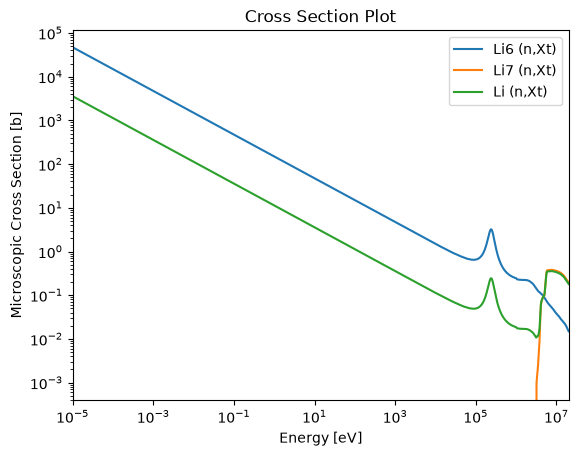

In [2]:
_ = openmc.plotter.plot_xs(
    reactions = {
        'Li6': ['(n,Xt)'],
        'Li7': ['(n,Xt)'],
        'Li': ['(n,Xt)'],
    }
)

## 1. Materials

In [3]:
# https://docs.openmc.org/en/stable/pythonapi/generated/openmc.Material.html
mats_df = pd.DataFrame(columns=[
    'name', 'element', 'percent', 'percent_type',
    'enrichment', 'enrichment_target', 'enrichment_type'
])
mats_df.loc[len(mats_df)] = ['breeder', 'Pb', 84.2, 'ao'] + 3 * [None]
mats_df.loc[len(mats_df)] = ['breeder', 'Li', 15.8, 'ao', 50, 'Li6', 'ao']
mats_df.loc[len(mats_df)] = ['steel', 'Fe', 0.95, 'wo'] + 3 * [None]
mats_df.loc[len(mats_df)] = ['steel', 'C', 0.05, 'wo'] + 3 * [None]
mats_df

,name,element,percent,percent_type,enrichment,enrichment_target,enrichment_type
0,breeder,Pb,84.20,ao,None,None,None
1,breeder,Li,15.80,ao,50,Li6,ao
2,steel,Fe,0.95,wo,None,None,None
3,steel,C,0.05,wo,None,None,None


In [4]:
mats_dic = {}
for name, dat in mats_df.groupby('name'):
    mats_dic[name] = openmc.Material(name=name)

    for _, row in dat.drop(columns='name').iterrows():
        mats_dic[name].add_element(**row.dropna().to_dict())

mats_dic['breeder'].set_density('atom/b-cm', 3.2720171e-2)
mats_dic['steel'].set_density('g/cm3', 7.75)
mats_dic

{'breeder': Material
 	ID             =	1
 	Name           =	breeder
 	Temperature    =	None
 	Density        =	0.032720171 [atom/b-cm]
 	Volume         =	None [cm^3]
 	Depletable     =	False
 	S(a,b) Tables  
 	Nuclides       
 	Pb204          =	1.1788       [ao]
 	Pb206          =	20.2922      [ao]
 	Pb207          =	18.6082      [ao]
 	Pb208          =	44.1208      [ao]
 	Li6            =	7.9          [ao]
 	Li7            =	7.9          [ao],
 'steel': Material
 	ID             =	2
 	Name           =	steel
 	Temperature    =	None
 	Density        =	7.75 [g/cm3]
 	Volume         =	None [cm^3]
 	Depletable     =	False
 	S(a,b) Tables  
 	Nuclides       
 	Fe54           =	0.053632803115715125 [wo]
 	Fe56           =	0.8730645234058433 [wo]
 	Fe57           =	0.020523501829909044 [wo]
 	Fe58           =	0.002779171648532559 [wo]
 	C12            =	0.04940034225428433 [wo]
 	C13            =	0.0005996577457156737 [wo]}

In [5]:
model = {}
model['materials'] = openmc.Materials(mats_dic.values())

## 2. Geometry

In [6]:
geom_df = pd.DataFrame(
    columns=['radius_cm', 'boundary_type', 'region', 'mats']
)
geom_df.loc['vessel_inner'] = [500, None, '-vessel_inner', None]
geom_df.loc['first_wall'] = [510, None, '-first_wall & +vessel_inner', 'steel']
geom_df.loc['breeder_blanket'] = [
    610, 'vacuum', '+first_wall & -breeder_blanket', 'breeder'
]
geom_df

,radius_cm,boundary_type,region,mats
vessel_inner,500,None,-vessel_inner,None
first_wall,510,None,-first_wall & +vessel_inner,steel
breeder_blanket,610,vacuum,+first_wall & -breeder_blanket,breeder


In [7]:
# Ensure that all surfaces referenced in region expressions are 
# defined in geom_df.index.
assert all(
    name in geom_df.index
    for region in geom_df['region']
    for name in re.findall(r'\b\w+\b', region)
)

In [8]:
sphere = {}
for name, dat in geom_df.iterrows():
    sphere[name] = openmc.Sphere(
        r=dat['radius_cm'],
        **dat[['boundary_type']].dropna().to_dict()
    )

In [9]:
# Convert named surface expressions into OpenMC regions.
# https://docs.openmc.org/en/stable/pythonapi/generated/openmc.Region.html

surfaces = {s.id: s for s in sphere.values()}

def str2region(string):
    for name, surface in sphere.items():
        string = string.replace(name, str(surface.id))

    string = string.replace('&', ' ')

    return openmc.Region.from_expression(string, surfaces)

geom = {}
for name, dat in geom_df.iterrows():
    geom[name] = openmc.Cell(
        name=name,
        region=str2region(dat['region']),
        fill=mats_dic.get(dat['mats'])
    )

model['geometry'] = openmc.Geometry(geom.values())

## 3. Mean free paths

In [10]:
for name, mat in mats_dic.items():
    geom_df.loc[geom_df['mats'] == name, 'mfp@14MeV_cm'] = (
        mat.mean_free_path(source_eV)
    )

geom_df

,radius_cm,boundary_type,region,mats,mfp@14MeV_cm
vessel_inner,500,None,-vessel_inner,None,NaN
first_wall,510,None,-first_wall & +vessel_inner,steel,4.342932
breeder_blanket,610,vacuum,+first_wall & -breeder_blanket,breeder,6.500664


## 4. Settings (with source)

In [11]:
model['settings'] = openmc.Settings()
model['settings'].batches = 10
model['settings'].particles = 10000
model['settings'].run_mode = 'fixed source'

# Adaptive stopping
model['settings'].trigger_active = True
model['settings'].trigger_max_batches = 100
model['settings'].trigger_batch_interval = 5

model['settings'].source = openmc.IndependentSource(
    space=openmc.stats.Point((0, 0, 0)),
    angle=openmc.stats.Isotropic(),
    energy=openmc.stats.Discrete([source_eV], [1])
)

## 5. Tally

$^6Li + n \rightarrow \alpha + T$

$^7Li + n \rightarrow \alpha + T + n$

For this simulation, the tritium breeding ratio (TBR) is the number of tritium nuclei produced per source neutron.

In [12]:
cell_filter = openmc.CellFilter(geom['breeder_blanket'])

model['tallies'] = openmc.Tallies([
    openmc.Tally(
        name='TBR',
        # Exclude vessel_inner and first_wall.
        filters=[cell_filter],
        scores=['H3-production'],
        nuclides=mats_dic['breeder'].get_nuclides() + ['total'],
    ),
    openmc.Tally(
        name='TBR_convergence',
        filters=[cell_filter],
        scores=['H3-production'],
        nuclides=['total'],
        triggers=[openmc.Trigger('rel_err', 0.01)],
    ),
])

## 6. Ready and plot
Due to the spherical symmetry of the geometry, plotting just one quadrant is good.

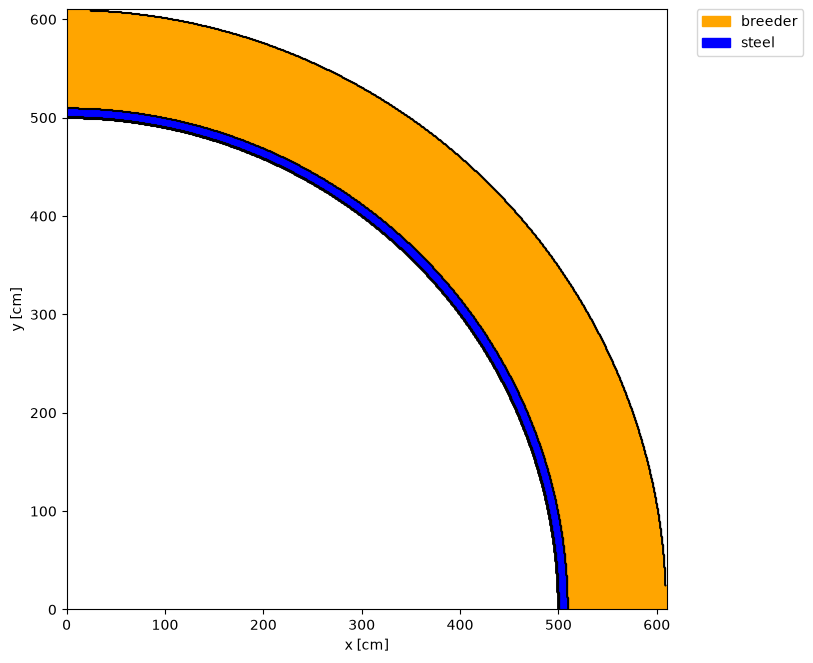

In [18]:
openmc_model = openmc.Model(**model)
colors = {
    mats_dic['breeder']: 'orange',
    mats_dic['steel']: 'blue',
}

R = 610

ax = openmc_model.plot(
    basis='xy',
    origin=(R/2, R/2, 0),
    width=(R, R),
    color_by='material',
    colors=colors,
    outline=True,
    legend=True,
    pixels=(600, 600),
)

In [14]:
openmc_model.geometry.bounding_box

BoundingBox(lower_left=(-610.0, -610.0, -610.0), upper_right=(610.0, 610.0, 610.0))

## 7. Run

In [15]:
sp_filename = openmc_model.run(cwd=output_dir)

                                %%%%%%%%%%%%%%%
                           %%%%%%%%%%%%%%%%%%%%%%%%
                        %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                      %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                    %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                   %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                                    %%%%%%%%%%%%%%%%%%%%%%%%
                                     %%%%%%%%%%%%%%%%%%%%%%%%
                 ###############      %%%%%%%%%%%%%%%%%%%%%%%%
                ##################     %%%%%%%%%%%%%%%%%%%%%%%
                ###################     %%%%%%%%%%%%%%%%%%%%%%%
                ####################     %%%%%%%%%%%%%%%%%%%%%%
                #####################     %%%%%%%%%%%%%%%%%%%%%
                ######################     %%%%%%%%%%%%%%%%%%%%
                #######################     %%%%%%%%%%%%%%%%%%
                 #######################     %%%%%%%%%%%%%%%%%
                 #####################

## 8. Output

In [16]:
with openmc.StatePoint(sp_filename) as sp:
    tally = sp.get_tally(name='TBR')
    df = tally.get_pandas_dataframe()

df['rel_err'] = df['std. dev.'] / df['mean'].abs()
df.sort_values('mean', ascending=False)

,cell,nuclide,score,mean,std. dev.,rel_err
6,3,total,"(n,Xt)",1.025967e+00,5.163707e-03,0.005033
4,3,Li6,"(n,Xt)",1.022352e+00,5.164871e-03,0.005052
5,3,Li7,"(n,Xt)",3.615261e-03,2.678243e-05,0.007408
3,3,Pb208,"(n,Xt)",7.231948e-08,6.946750e-10,0.009606
2,3,Pb207,"(n,Xt)",2.367304e-08,2.290226e-10,0.009674
0,3,Pb204,"(n,Xt)",1.767367e-08,1.719513e-10,0.009729
1,3,Pb206,"(n,Xt)",0.000000e+00,0.000000e+00,NaN
